epoch  1000  total=1.88e-01  pde=1.41e-02  ic=1.40e-03  bc=3.44e-04
epoch  2000  total=7.03e-02  pde=6.68e-03  ic=5.56e-04  bc=7.95e-05
epoch  3000  total=3.36e-02  pde=4.64e-03  ic=2.50e-04  bc=3.91e-05
epoch  4000  total=1.27e-02  pde=2.08e-03  ic=9.37e-05  bc=1.27e-05
epoch  5000  total=3.16e-03  pde=1.14e-03  ic=1.05e-05  bc=9.70e-06
epoch  6000  total=1.12e-03  pde=6.93e-04  ic=2.53e-06  bc=1.76e-06
epoch  7000  total=7.91e-04  pde=4.67e-04  ic=2.20e-06  bc=1.03e-06
epoch  8000  total=1.32e-03  pde=3.46e-04  ic=4.32e-06  bc=5.38e-06
epoch  9000  total=1.07e-02  pde=2.76e-04  ic=4.10e-05  bc=6.31e-05
epoch 10000  total=5.97e-04  pde=2.33e-04  ic=2.64e-06  bc=9.97e-07

relative L2 error: 0.0047 (0.47%)


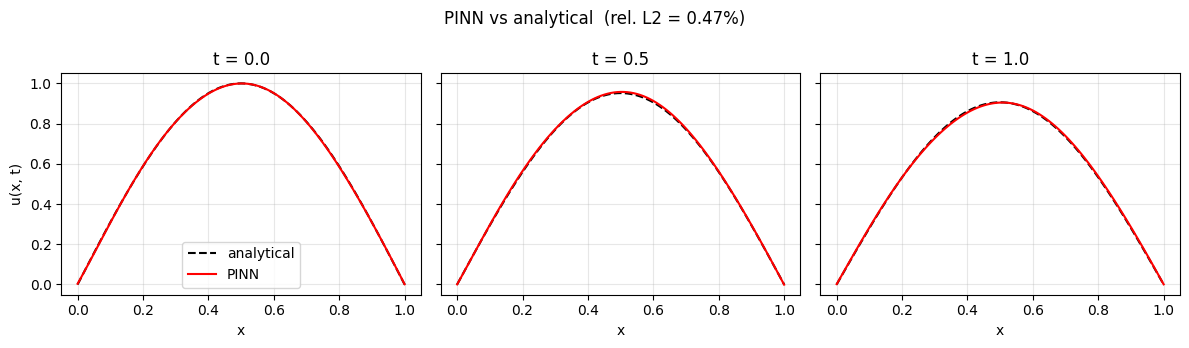

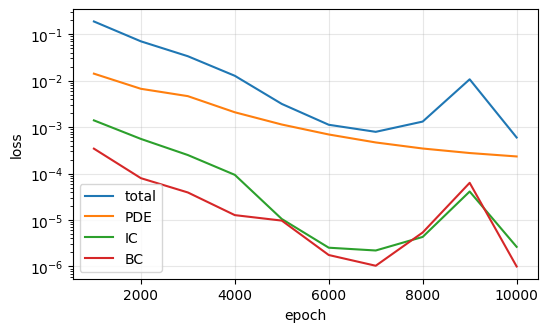

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# ---------- config ----------
alpha = 0.01          # diffusion coefficient
T = 1.0               # time domain [0, T]
N_f, N_ic, N_bc = 1000, 200, 200
lam_ic = lam_bc = 100.0   # IC/BC weight vs PDE residual
epochs, lr = 10000, 1e-3
tf.random.set_seed(0); np.random.seed(0)

# ---------- model (same arch as yours) ----------
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(2,)),
    tf.keras.layers.Dense(50, activation='tanh'),
    tf.keras.layers.Dense(50, activation='tanh'),
    tf.keras.layers.Dense(1),
])

# ---------- data ----------
X_f  = np.random.rand(N_f, 2) * [1.0, T]                       # interior (x, t)
X_ic = np.column_stack([np.random.rand(N_ic), np.zeros(N_ic)]) # t = 0
u_ic = np.sin(np.pi * X_ic[:, 0:1])                             # u(x,0) = sin(pi x)
t_bc = np.random.rand(N_bc, 1) * T
X_bc = np.vstack([np.column_stack([np.zeros(N_bc), t_bc[:, 0]]),  # x = 0
                  np.column_stack([np.ones(N_bc),  t_bc[:, 0]])])  # x = 1
u_bc = np.zeros((2 * N_bc, 1))                                  # u(0,t) = u(1,t) = 0

X_f  = tf.convert_to_tensor(X_f, dtype=tf.float32)
X_ic = tf.convert_to_tensor(X_ic, dtype=tf.float32)
u_ic = tf.convert_to_tensor(u_ic, dtype=tf.float32)
X_bc = tf.convert_to_tensor(X_bc, dtype=tf.float32)
u_bc = tf.convert_to_tensor(u_bc, dtype=tf.float32)
opt = tf.keras.optimizers.Adam(lr)

@tf.function
def train_step():
    with tf.GradientTape() as tape:                       # param grads
        with tf.GradientTape(persistent=True) as g2:
            with tf.GradientTape(persistent=True) as g1:
                g1.watch(X_f); g2.watch(X_f)
                u = model(X_f)
            u_x = g1.gradient(u, X_f)[:, 0:1]
            u_t = g1.gradient(u, X_f)[:, 1:2]
        u_xx = g2.gradient(u_x, X_f)[:, 0:1]
        f = u_t - alpha * u_xx                            # PDE residual
        loss_f  = tf.reduce_mean(tf.square(f))
        loss_ic = tf.reduce_mean(tf.square(model(X_ic) - u_ic))
        loss_bc = tf.reduce_mean(tf.square(model(X_bc) - u_bc))
        loss = loss_f + lam_ic * loss_ic + lam_bc * loss_bc
    grads = tape.gradient(loss, model.trainable_variables)
    opt.apply_gradients(zip(grads, model.trainable_variables))
    return loss, loss_f, loss_ic, loss_bc

# ---------- train ----------
hist = []
for ep in range(1, epochs + 1):
    loss, lf, lic, lbc = train_step()
    if ep % 1000 == 0:
        hist.append((float(loss), float(lf), float(lic), float(lbc)))
        print(f"epoch {ep:5d}  total={loss:.2e}  pde={lf:.2e}  ic={lic:.2e}  bc={lbc:.2e}")

# ---------- validate vs analytical u(x,t) = sin(pi x) * exp(-alpha pi^2 t) ----------
nx, nt = 101, 101
xs = np.linspace(0, 1, nx); ts = np.linspace(0, T, nt)
XX, TT = np.meshgrid(xs, ts)
Xg = np.column_stack([XX.ravel(), TT.ravel()]).astype(np.float32)
u_pred  = model(Xg).numpy().reshape(nt, nx)
u_exact = np.sin(np.pi * XX) * np.exp(-alpha * np.pi**2 * TT)
rel_l2 = np.linalg.norm(u_pred - u_exact) / np.linalg.norm(u_exact)
print(f"\nrelative L2 error: {rel_l2:.4f} ({100*rel_l2:.2f}%)")

# ---------- plots ----------
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, t_snap in zip(axes, [0.0, 0.5, 1.0]):
    j = int(t_snap / T * (nt - 1))
    ax.plot(xs, u_exact[j], 'k--', label='analytical')
    ax.plot(xs, u_pred[j], 'r-', label='PINN')
    ax.set_title(f"t = {t_snap}"); ax.set_xlabel("x"); ax.grid(alpha=0.3)
axes[0].set_ylabel("u(x, t)"); axes[0].legend()
fig.suptitle(f"PINN vs analytical  (rel. L2 = {rel_l2:.2%})")
plt.tight_layout(); plt.show()

h = np.array(hist)
plt.figure(figsize=(6, 3.5))
for k, name in enumerate(["total", "PDE", "IC", "BC"]):
    plt.semilogy(np.arange(1, len(h) + 1) * 1000, h[:, k], label=name)
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.grid(alpha=0.3)
plt.show()


In [1]:
import torch
import torch.nn as nn

# 1. Define the Neural Network
class LevelSetPINN(nn.Module):
    def __init__(self):
        super(LevelSetPINN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(3, 32), # inputs: (t, x, y)
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 1)  # output: u(t, x, y)
        )

    def forward(self, t, x, y):
        inputs = torch.cat([t, x, y], dim=-1)
        return self.net(inputs)

# 2. Compute Physics Residual (e.g., u_t + S * ||grad u|| = 0)
def pde_residual(model, t, x, y, S=1.0):
    u = model(t, x, y)

    # First derivatives via autograd
    grads = torch.autograd.grad(
        u, [t, x, y],
        grad_outputs=torch.ones_like(u),
        create_graph=True,
        retain_graph=True
    )
    u_t, u_x, u_y = grads[0], grads[1], grads[2]

    # Gradient norm ||grad u||
    grad_norm = torch.sqrt(u_x**2 + u_y**2 + 1e-8)

    # Governing Level Set residual
    residual = u_t + S * grad_norm
    return residual


In [24]:
import torch
import torch.nn as nn
import numpy as np

# --- 1. Define Model Architecture ---
class LevelSetPINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, 64), nn.Tanh(), # Corrected: changed from 2 to 3
            nn.Linear(64, 64), nn.Tanh(),
            nn.Linear(64, 64), nn.Tanh(),
            nn.Linear(64, 1)
        )
    def forward(self, t, x, y):
        return self.net(torch.cat([t, x, y], dim=-1))

# --- 2. Initial Condition Definition (Circle of radius 0.2 at t=0) ---
def get_signed_distance_circle(x, y, r=0.2):
    return torch.sqrt(x**2 + y**2) - r

# --- 3. Training Point Generation ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = LevelSetPINN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# Sample N points inside the spacetime box: x in [-1,1], y in [-1,1], t in [0, 0.5]
N_pde = 5000
t_pde = torch.rand(N_pde, 1, requires_grad=True, device=device) * 0.5
x_pde = torch.rand(N_pde, 1, requires_grad=True, device=device) * 2.0 - 1.0
y_pde = torch.rand(N_pde, 1, requires_grad=True, device=device) * 2.0 - 1.0

# Initial condition points (t = 0)
N_ic = 1000
t_ic = torch.zeros(N_ic, 1, device=device)
x_ic = torch.rand(N_ic, 1, device=device) * 2.0 - 1.0
y_ic = torch.rand(N_ic, 1, device=device) * 2.0 - 1.0
u_ic_target = get_signed_distance_circle(x_ic, y_ic)

# --- 4. Optimization Loop ---
for epoch in range(2001):
    optimizer.zero_grad()

    # A. Initial Condition Loss
    u_ic_pred = model(t_ic, x_ic, y_ic)
    loss_ic = torch.mean((u_ic_pred - u_ic_target)**2)

    # B. PDE Residual Loss and C. Eikonal regularizer
    # Calculate gradients for Eikonal Loss.
    # We need to compute 'u' and its spatial gradients for the Eikonal term.
    # We explicitly compute it here, ensuring create_graph and retain_graph are set.
    # Note: t_pde is NOT part of the gradient calculation for the Eikonal term's grad_norm.
    u_eikonal = model(t_pde, x_pde, y_pde)
    # The autograd.grad for eikonal only needs spatial gradients
    grads_spatial = torch.autograd.grad(
        u_eikonal, [x_pde, y_pde],
        grad_outputs=torch.ones_like(u_eikonal),
        create_graph=True,
        retain_graph=True # Retain graph since pde_residual_with_variable_R will also use the model output 'u'
    )
    u_x_eik, u_y_eik = grads_spatial[0], grads_spatial[1]
    grad_norm_eik = torch.sqrt(u_x_eik**2 + u_y_eik**2 + 1e-8)

    # C. Eikonal regularizer (forces ||grad u|| = 1)
    loss_eik = torch.mean((grad_norm_eik - 1.0)**2)

    # Now, calculate the PDE Residual Loss using the new function
    pde_res_variable_R = pde_residual_with_variable_R(
        model, t_pde, x_pde, y_pde, dummy_fuel_map, wind_speed_t
    )
    loss_pde = torch.mean(pde_res_variable_R**2)

    # Total Loss and update
    loss = 10.0 * loss_ic + 1.0 * loss_pde + 0.1 * loss_eik
    loss.backward(retain_graph=True)
    optimizer.step()

    if epoch % 500 == 0:
        print(f"Epoch {epoch:4d} | IC Loss: {loss_ic.item():.4f} | PDE Loss: {loss_pde.item():.4f} | Eikonal Loss: {loss_eik.item():.4f}")

TypeError: unsupported operand type(s) for ** or pow(): 'tuple' and 'int'

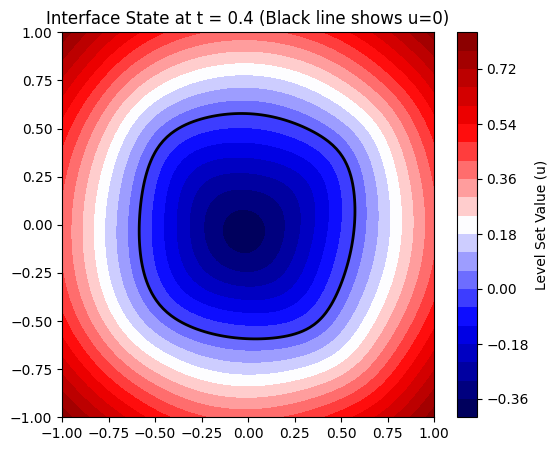

In [9]:
import matplotlib.pyplot as plt

# Generate a grid for plotting at final time t = 0.4
grid_res = 100
x_space = np.linspace(-1, 1, grid_res)
y_space = np.linspace(-1, 1, grid_res)
X, Y = np.meshgrid(x_space, y_space)

# Flatten grid to feed into network
t_eval = torch.full((grid_res * grid_res, 1), 0.4, device=device)
x_eval = torch.tensor(X.flatten()[:, None], dtype=torch.float32, device=device)
y_eval = torch.tensor(Y.flatten()[:, None], dtype=torch.float32, device=device)

with torch.no_grad():
    Z = model(t_eval, x_eval, y_eval).cpu().numpy().reshape(grid_res, grid_res)

# Interpret boundaries
plt.figure(figsize=(6,5))
# Contour level at 0 is the actual interface position
cp = plt.contourf(X, Y, Z, levels=20, cmap='seismic')
plt.colorbar(cp, label="Level Set Value (u)")
# Highlight the zero-level set boundary explicitly
plt.contour(X, Y, Z, levels=[0], colors='black', linewidths=2)
plt.title("Interface State at t = 0.4 (Black line shows u=0)")
plt.show()


### Visualizing the Initial Condition (t=0)
Let's plot the model's prediction at `t=0` to see how well it captures the initial circle.

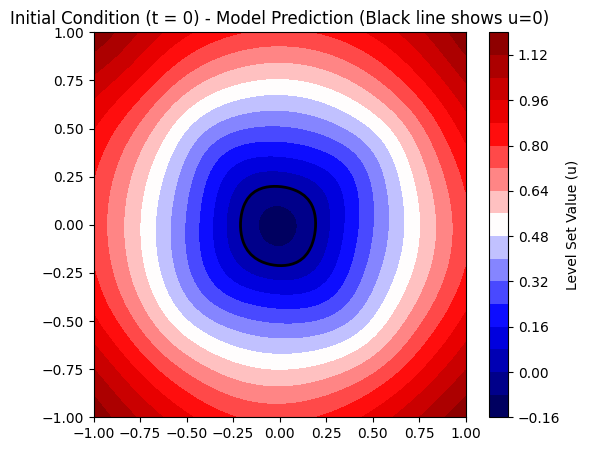

In [15]:
# Generate a grid for plotting at t = 0
grid_res = 100
x_space = np.linspace(-1, 1, grid_res)
y_space = np.linspace(-1, 1, grid_res)
X_0, Y_0 = np.meshgrid(x_space, y_space)

# Flatten grid to feed into network
t_eval_0 = torch.full((grid_res * grid_res, 1), 0.0, device=device)
x_eval_0 = torch.tensor(X_0.flatten()[:, None], dtype=torch.float32, device=device)
y_eval_0 = torch.tensor(Y_0.flatten()[:, None], dtype=torch.float32, device=device)

with torch.no_grad():
    Z_0 = model(t_eval_0, x_eval_0, y_eval_0).cpu().numpy().reshape(grid_res, grid_res)

plt.figure(figsize=(6,5))
cp = plt.contourf(X_0, Y_0, Z_0, levels=20, cmap='seismic')
plt.colorbar(cp, label="Level Set Value (u)")
plt.contour(X_0, Y_0, Z_0, levels=[0], colors='black', linewidths=2)
plt.title("Initial Condition (t = 0) - Model Prediction (Black line shows u=0)")
plt.show()

In [10]:
import numpy as np
from skimage import measure
import torch

def export_interface_mesh(model, target_time, resolution=128):
    """Extracts the exact u=0 boundary as a mesh of vertices and faces."""
    # 1. Create a fine grid evaluation bounding box
    lin = np.linspace(-1.0, 1.0, resolution)
    X, Y = np.meshgrid(lin, lin)

    # 2. Format grid for PyTorch inference
    t_eval = torch.full((resolution * resolution, 1), target_time, dtype=torch.float32)
    x_eval = torch.tensor(X.flatten()[:, None], dtype=torch.float32)
    y_eval = torch.tensor(Y.flatten()[:, None], dtype=torch.float32)

    with torch.no_grad():
        # Get predictions and reshape back to a 2D image array
        Z = model(t_eval, x_eval, y_eval).numpy().reshape(resolution, resolution)

    # 3. Use Marching Squares/Cubes to isolate the exact 0.0 contour line
    contours = measure.find_contours(Z, level=0.0)

    # 4. Map pixel indexes back to physical coordinate space
    physical_contours = []
    for contour in contours:
        real_x = -1.0 + (contour[:, 1] / (resolution - 1)) * 2.0
        real_y = -1.0 + (contour[:, 0] / (resolution - 1)) * 2.0
        physical_contours.append(np.stack([real_x, real_y], axis=1))

    return physical_contours  # List of coordinates tracking the outer boundary


In [11]:
def check_containment(model, time, x_coord, y_coord):
    """Instantly checks if a coordinate is inside, outside, or on the boundary."""
    t_tensor = torch.tensor([[time]], dtype=torch.float32)
    x_tensor = torch.tensor([[x_coord]], dtype=torch.float32)
    y_tensor = torch.tensor([[y_coord]], dtype=torch.float32)

    with torch.no_grad():
        u_val = model(t_tensor, x_tensor, y_tensor).item()

    if u_val < -1e-3:
        return "INSIDE the boundary structure"
    elif u_val > 1e-3:
        return "OUTSIDE the boundary structure"
    else:
        return "EXACTLY ON the interface edge"


In [12]:
def get_surface_normals(model, t, x, y):
    """Calculates the exact direction the shape's boundary is facing."""
    # Ensure gradients can be tracked
    t.requires_grad_(True)
    x.requires_grad_(True)
    y.requires_grad_(True)

    u = model(t, x, y)

    # Take analytical spatial derivatives via PyTorch Autograd
    grads = torch.autograd.grad(u, [x, y], torch.ones_like(u), create_graph=True)
    u_x, u_y = grads[0], grads[1]

    grad_norm = torch.sqrt(u_x**2 + u_y**2 + 1e-8)

    # Directional normal vectors pointing outward from the surface
    nx = u_x / grad_norm
    ny = u_y / grad_norm

    return nx.detach(), ny.detach()


In [13]:
def wildfire_pde_residual(model, t, x, y, fuel_spread_rate, wind_x, wind_y):
    u = model(t, x, y)

    # Take derivatives relative to time and space
    grads = torch.autograd.grad(u, [t, x, y], torch.ones_like(u), create_graph=True)
    u_t, u_x, u_y = grads[0], grads[1], grads[2]

    grad_norm = torch.sqrt(u_x**2 + u_y**2 + 1e-8)

    # Wildfire level set equation:
    # Fire moves at its base fuel rate (R) + gets pushed along the wind vector
    advection_term = wind_x * u_x + wind_y * u_y
    pde_residual = u_t + advection_term + (fuel_spread_rate * grad_norm)

    return pde_residual


In [14]:
export_interface_mesh(model, target_time=10)

[]

### Demonstrating `check_containment`
Let's test the `check_containment` function with a specific point at `t=0.4`.

In [16]:
# Example usage of check_containment
test_time = 0.4
test_x_inside = 0.1
test_y_inside = 0.1
test_x_outside = 0.8
test_y_outside = 0.8

status_inside = check_containment(model, test_time, test_x_inside, test_y_inside)
status_outside = check_containment(model, test_time, test_x_outside, test_y_outside)

print(f"Point ({test_x_inside}, {test_y_inside}) at t={test_time}: {status_inside}")
print(f"Point ({test_x_outside}, {test_y_outside}) at t={test_time}: {status_outside}")

Point (0.1, 0.1) at t=0.4: INSIDE the boundary structure
Point (0.8, 0.8) at t=0.4: OUTSIDE the boundary structure


### Demonstrating `get_surface_normals`
Let's visualize the surface normals at a few points along the interface at `t=0.4`.

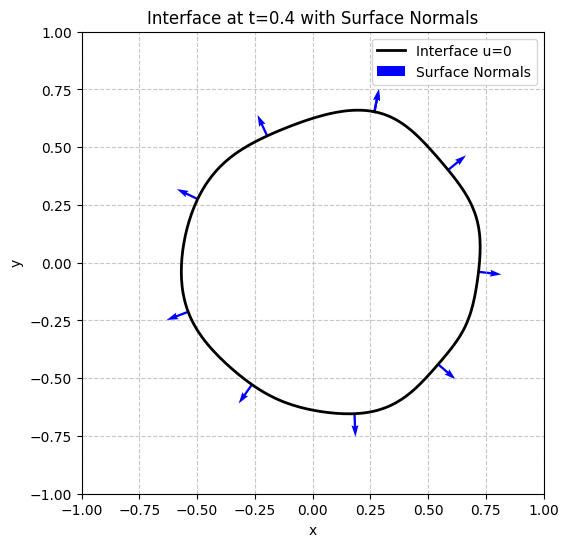

In [31]:
import matplotlib.pyplot as plt

# Get the interface points for visualization of normals
interface_contours = export_interface_mesh(model, target_time=0.4)

plt.figure(figsize=(7,6))

# Plot the interface
if interface_contours:
    for contour in interface_contours:
        plt.plot(contour[:, 0], contour[:, 1], 'k-', linewidth=2, label='Interface u=0')

# Sample points on the interface to plot normals
# We'll take a few points from the first contour if it exists
if interface_contours and len(interface_contours[0]) > 5:
    # Sample a few points for plotting normals
    sample_indices = np.linspace(0, len(interface_contours[0]) - 1, 10, dtype=int)
    sample_points = torch.tensor(interface_contours[0][sample_indices], dtype=torch.float32)

    t_normals = torch.full((sample_points.shape[0], 1), 0.4, device=device, requires_grad=True)
    x_normals = sample_points[:, 0:1].to(device).clone().detach().requires_grad_(True)
    y_normals = sample_points[:, 1:2].to(device).clone().detach().requires_grad_(True)

    nx, ny = get_surface_normals(model, t_normals, x_normals, y_normals)

    # Plot normals
    plt.quiver(x_normals.cpu().detach().numpy(), y_normals.cpu().detach().numpy(),
               nx.cpu().detach().numpy(), ny.cpu().detach().numpy(),
               color='blue', scale=20, width=0.005, label='Surface Normals')

plt.title("Interface at t=0.4 with Surface Normals")
plt.xlabel("x"); plt.ylabel("y")
plt.grid(True, linestyle='--', alpha=0.7)
plt.gca().set_aspect('equal', adjustable='box')
plt.xlim([-1, 1]); plt.ylim([-1, 1])
plt.legend()
plt.show()

### Animating the Interface Evolution
Let's see how the interface changes over time using `export_interface_mesh`.

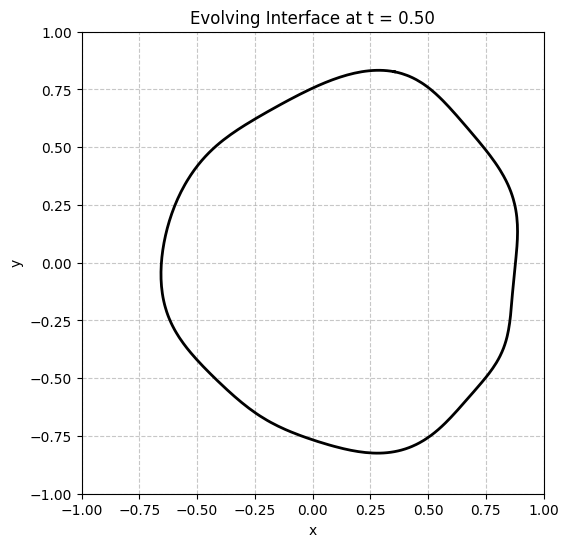

In [30]:
import matplotlib.animation as animation
from IPython.display import HTML

# Define the time steps for the animation
time_steps = np.linspace(0, 0.5, 20) # 20 frames from t=0 to t=0.5

fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim([-1, 1])
ax.set_ylim([-1, 1])
ax.set_title("Evolving Interface")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_aspect('equal', adjustable='box')
ax.grid(True, linestyle='--', alpha=0.7)

line, = ax.plot([], [], 'k-', lw=2)

def animate(i):
    current_time = time_steps[i]
    ax.set_title(f"Evolving Interface at t = {current_time:.2f}")
    contours = export_interface_mesh(model, target_time=current_time)
    if contours:
        # Assuming we are interested in the largest contour if multiple are found
        largest_contour = max(contours, key=len)
        line.set_data(largest_contour[:, 0], largest_contour[:, 1])
    else:
        line.set_data([], []) # Clear data if no contour is found
    return line,

anim = animation.FuncAnimation(fig, animate, frames=len(time_steps), interval=200, blit=True)

# Display the animation
HTML(anim.to_jshtml())

### 3D Visualization: Isosurface of `u=0` in `(x, y, t)` spacetime
To get a full picture of the interface's evolution, we can visualize the `u=0` isosurface in 3D spacetime, where the axes represent `x`, `y`, and `t`. This will show the trajectory of the interface as a 2D surface embedded in 3D space. We'll use `skimage.measure.marching_cubes` to extract this surface.

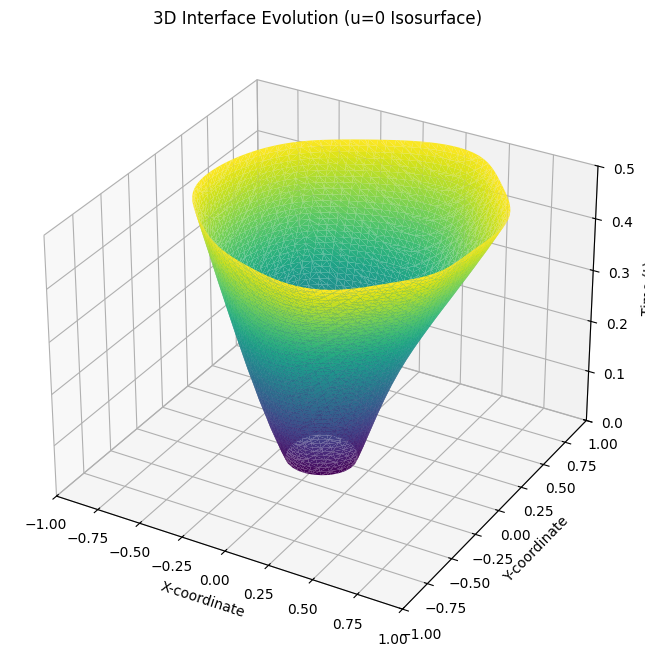

In [32]:
from mpl_toolkits.mplot3d import Axes3D
from skimage import measure

# Define the resolution for the 3D grid
res_x, res_y, res_t = 50, 50, 50

# Create 3D grid for x, y, and t
x_space_3d = np.linspace(-1, 1, res_x)
y_space_3d = np.linspace(-1, 1, res_y)
t_space_3d = np.linspace(0, 0.5, res_t) # Time from 0 to 0.5

# Create meshgrids for 3D evaluation
T_3D, X_3D, Y_3D = np.meshgrid(t_space_3d, x_space_3d, y_space_3d, indexing='ij')

# Flatten and convert to tensors for model prediction
t_eval_3d = torch.tensor(T_3D.flatten()[:, None], dtype=torch.float32, device=device)
x_eval_3d = torch.tensor(X_3D.flatten()[:, None], dtype=torch.float32, device=device)
y_eval_3d = torch.tensor(Y_3D.flatten()[:, None], dtype=torch.float32, device=device)

with torch.no_grad():
    # Get predictions and reshape back to a 3D array (res_t, res_x, res_y)
    U_3D = model(t_eval_3d, x_eval_3d, y_eval_3d).cpu().numpy().reshape(res_t, res_x, res_y)

# Use Marching Cubes to find the isosurface where U_3D = 0
# The output vertices and faces are relative to the grid indices.
verts, faces, _, _ = measure.marching_cubes(U_3D, level=0.0,
                                              spacing=(t_space_3d[1]-t_space_3d[0],
                                                       x_space_3d[1]-x_space_3d[0],
                                                       y_space_3d[1]-y_space_3d[0]))

# Scale vertices to actual physical coordinates
verts_scaled = np.array([t_space_3d[0] + verts[:, 0],
                         x_space_3d[0] + verts[:, 1],
                         y_space_3d[0] + verts[:, 2]]).T

# Plotting the 3D isosurface
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

ax.plot_trisurf(verts_scaled[:, 1], verts_scaled[:, 2], faces, verts_scaled[:, 0],
                cmap='viridis', lw=0.1)

ax.set_xlabel('X-coordinate')
ax.set_ylabel('Y-coordinate')
ax.set_zlabel('Time (t)')
ax.set_title('3D Interface Evolution (u=0 Isosurface)')
ax.set_xlim([-1, 1])
ax.set_ylim([-1, 1])
ax.set_zlim([0, 0.5])

plt.show()

In [33]:
import torch
import numpy as np

# Define the analytical solution for an expanding circle with constant R
def analytical_expanding_circle(t, x, y, R_const=1.0, r0=0.2):
    """Calculates the analytical level set value for an expanding circle.
    u(t,x,y) = sqrt(x^2 + y^2) - (R_const * t + r0)
    """
    radius_at_t = R_const * t + r0
    return torch.sqrt(x**2 + y**2) - radius_at_t

# Reuse the 3D evaluation grid points from the previous cell (d93dc86e)
# Ensure t_eval_3d, x_eval_3d, y_eval_3d are still available or re-create them if needed.
# For safety, let's re-create the tensors here, ensuring they are on the correct device.

# Define the resolution for the 3D grid
res_x, res_y, res_t = 50, 50, 50

# Create 3D grid for x, y, and t
x_space_3d = np.linspace(-1, 1, res_x)
y_space_3d = np.linspace(-1, 1, res_y)
t_space_3d = np.linspace(0, 0.5, res_t) # Time from 0 to 0.5

# Create meshgrids for 3D evaluation
T_3D, X_3D, Y_3D = np.meshgrid(t_space_3d, x_space_3d, y_space_3d, indexing='ij')

# Flatten and convert to tensors for model prediction and analytical evaluation
t_eval_3d_flat = torch.tensor(T_3D.flatten()[:, None], dtype=torch.float32, device=device)
x_eval_3d_flat = torch.tensor(X_3D.flatten()[:, None], dtype=torch.float32, device=device)
y_eval_3d_flat = torch.tensor(Y_3D.flatten()[:, None], dtype=torch.float32, device=device)

# Set constant R and initial radius based on our problem definition
CONSTANT_R = 1.0 # Assuming a constant speed of 1.0 for analytical comparison
INITIAL_RADIUS = 0.2 # From the initial condition definition

# Get model predictions
with torch.no_grad():
    u_pred_flat = model(t_eval_3d_flat, x_eval_3d_flat, y_eval_3d_flat)

# Get analytical solution values
u_analytical_flat = analytical_expanding_circle(
    t_eval_3d_flat, x_eval_3d_flat, y_eval_3d_flat,
    R_const=CONSTANT_R, r0=INITIAL_RADIUS
)

# Calculate relative L2 error
relative_l2_error = torch.norm(u_pred_flat - u_analytical_flat) / torch.norm(u_analytical_flat)

print(f"Relative L2 error vs. analytical expanding circle (R={CONSTANT_R}, r0={INITIAL_RADIUS}): {relative_l2_error.item():.4e}")

Relative L2 error vs. analytical expanding circle (R=1.0, r0=0.2): 1.6787e-01


### 2. The Wind-Ellipse Test

Now, let's implement the 'wind-ellipse test'. This involves defining a spatially varying `R` function that, for a uniform wind, should lead to an expanding ellipse. This is a critical validation step for the `pde_residual_with_variable_R` function.

We need to define a new `lookup_fuel_speed` function that incorporates an angular dependence for `R`, such that $R(x, y) = R_0(1 + c \cdot \cos(\theta - \theta_w))$, where $\theta$ is the angle from the positive x-axis, and $\theta_w$ is the wind direction.

First, let's redefine the `lookup_fuel_speed` function to implement this angular dependence. We will assume $R_0=1.0$, $c=0.5$, and $\theta_w = 0$ (wind blowing along the positive x-axis) for simplicity.

In [34]:
import math

def lookup_fuel_speed_wind_ellipse(x, y, R0=1.0, c=0.5, theta_w=0.0):
    """Calculates R(x,y) for the wind-ellipse test.
    R(x,y) = R0 * (1 + c * cos(theta - theta_w))
    where theta is the angle of (x,y) from the origin.
    """
    # Calculate angle theta for each (x,y) point
    theta = torch.atan2(y, x) # atan2 returns angle in (-pi, pi]

    # Calculate R with angular dependence
    local_R = R0 * (1 + c * torch.cos(theta - theta_w))

    return local_R

# Redefine dummy_fuel_map to use this new function in the training loop
# The actual `lookup_fuel_speed` argument will be `lookup_fuel_speed_wind_ellipse`
# and `dummy_fuel_map` will simply pass its parameters, or we can make `pde_residual_with_variable_R`
# directly take R_func.
# For now, let's modify the `wind_speed_t` to be constant for this test and pass a function.

# Let's ensure wind_speed_t is a constant factor for this specific test
def wind_speed_t_constant(t):
    return torch.zeros_like(t) # No time-dependent wind for this test

print("Defined `lookup_fuel_speed_wind_ellipse` and `wind_speed_t_constant`.")

Defined `lookup_fuel_speed_wind_ellipse` and `wind_speed_t_constant`.


Now we need to update the `pde_residual_with_variable_R` function and the training loop (`ESZIXhHTQ_OR` and `1b4ded9d`) to use this new `lookup_fuel_speed_wind_ellipse` function and `wind_speed_t_constant`. We will assume the analytical solution for an ellipse to calculate L2 error later.

Since the training loop is already in `1b4ded9d`, we'll modify it directly. We'll pass `lookup_fuel_speed_wind_ellipse` to `pde_residual_with_variable_R` which will then use its `x` and `y` inputs. Also, `wind_speed_t_constant` will be used to ensure the wind component is purely spatial for this test.

In [35]:
def pde_residual_with_variable_R(model, t, x, y, R_func, wind_speed_func):
    """
    PDE residual where R changes based on coordinate position (R_func)
    and current time (wind_speed_func).
    """
    u = model(t, x, y)

    # 1. Compute gradients
    grads = torch.autograd.grad(u, [t, x, y], torch.ones_like(u), create_graph=True)
    u_t, u_x, u_y = grads[0], grads[1], grads[2]
    grad_norm = torch.sqrt(u_x**2 + u_y**2 + 1e-8)

    # 2. Dynamically calculate local R for THESE specific points
    # R_func (e.g., lookup_fuel_speed_wind_ellipse) depends on x, y
    # wind_speed_func (e.g., wind_speed_t_constant) depends on t
    local_R = R_func(x, y) * (1.0 + wind_speed_func(t))

    # 3. Level set equation with dynamic R
    residual = u_t + local_R * grad_norm
    return residual

### Defining `fuel_map` and `wind_speed_t` (Placeholders)
Before using `pde_residual_with_variable_R`, we need to define the `fuel_map` (which dictates `R` based on `x, y` coordinates) and `wind_speed_t` (which adds a time-dependent factor to `R`). For demonstration, I'll create simple placeholder functions. In a real scenario, these would come from your specific physical model or data.

In [22]:
def lookup_fuel_speed(x, y, fuel_map_data=None):
    # For simplicity, let's assume a uniform fuel speed or a simple function of x,y
    # In a real application, fuel_map_data would be a grid or a more complex lookup structure
    # Here, we'll just return a base speed, possibly varying with x
    base_speed = 1.0 + 0.5 * torch.sin(np.pi * x)
    return base_speed

def wind_speed_t(t):
    # A simple time-dependent wind factor (e.g., oscillating wind speed)
    # It ensures the output is a tensor compatible with the inputs
    return 0.5 * torch.sin(2 * np.pi * t) # Example: wind factor between -0.5 and 0.5

# A dummy fuel_map (not directly used by lookup_fuel_speed as defined above,
# but kept for API consistency if lookup_fuel_speed were to be more complex)
dummy_fuel_map = None

### Integrating `pde_residual_with_variable_R` into the Training Loop
Now, we can update the training loop in cell `ESZIXhHTQ_OR` to use the more advanced PDE residual. We will replace the constant `S=1.0` with the dynamically calculated `local_R`.

In [23]:
# To avoid re-running the entire notebook, I'll show the changes needed in the relevant section.
# You would replace the 'B. PDE Residual Loss' part in your existing training loop (cell ESZIXhHTQ_OR) with this:

# --- Proposed change for B. PDE Residual Loss in cell ESZIXhHTQ_OR ---
# u = model(t_pde, x_pde, y_pde)
# # This is where we call the new function with the defined dependencies
# pde_res_variable_R = pde_residual_with_variable_R(
#     model, t_pde, x_pde, y_pde, dummy_fuel_map, wind_speed_t
# )
# loss_pde = torch.mean(pde_res_variable_R**2)

# Note: The pde_residual_with_variable_R function calculates the residual directly.
# It already handles the gradients, so you don't need a separate 'grads' call
# for u_t, u_x, u_y, and grad_norm within the training loop for the PDE residual if you use this function.

# If you intend to also use the eikonal regularizer, you will still need to calculate
# u_t, u_x, u_y and grad_norm *separately* from the `u` output of the model,
# similar to how it was done before, but ensuring `create_graph=True` and `retain_graph=True`
# are handled correctly if doing multiple backward passes or calculating higher-order gradients.

### Incorporating Real-World Observation Data
To incorporate real-world data, we first need to define a set of observation points and their corresponding values. Since we don't have actual files, we'll simulate some observations. These observations will serve as additional 'targets' for the PINN to learn from, complementing the physics-based losses.

In [28]:
# Simulate some 'real-world' observation data
N_obs = 500 # Number of observation points

# Randomly sample observation times (e.g., between t=0.1 and t=0.4)
t_obs = torch.rand(N_obs, 1, device=device) * 0.3 + 0.1

# Randomly sample observation spatial coordinates (e.g., within x=[-0.5, 0.5], y=[-0.5, 0.5])
x_obs = torch.rand(N_obs, 1, device=device) * 1.0 - 0.5
y_obs = torch.rand(N_obs, 1, device=device) * 1.0 - 0.5

# For the target values, let's use the analytical solution for a constant R=1 case
# to create realistic-looking observations, adding a bit of noise.
# This is just for demonstration; in reality, u_obs_target would come from measurements.
# The current PINN is trained for variable R, so these observations will help constrain it.

# Analytical solution for u_t + ||grad u|| = 0 with a circle IC:
# u(t,x,y) = sqrt(x^2 + y^2) - (R*t + r0)
# Here, let's assume R=1, r0=0.2 (from initial condition)
r0_analytical = 0.2
radius_at_obs_t = 1.0 * t_obs + r0_analytical # Assuming R=1 for these 'observations'
u_obs_target = torch.sqrt(x_obs**2 + y_obs**2) - radius_at_obs_t

# Add some noise to make it more like real-world data
u_obs_target += 0.01 * torch.randn_like(u_obs_target)

print(f"Generated {N_obs} observation points.")

Generated 500 observation points.


### Updating the Training Loop with Observation Loss
Now, we'll add a new loss term to the training loop that penalizes the model when its predictions at `(t_obs, x_obs, y_obs)` deviate from `u_obs_target`. We'll also introduce a weighting factor (`lambda_obs`) for this new loss term.

In [36]:
# Define a weight for the observation loss
lambda_obs = 100.0 # You might need to tune this weight

# --- 4. Optimization Loop (Modified) ---
for epoch in range(2001):
    optimizer.zero_grad()

    # A. Initial Condition Loss
    u_ic_pred = model(t_ic, x_ic, y_ic)
    loss_ic = torch.mean((u_ic_pred - u_ic_target)**2)

    # B. PDE Residual Loss and C. Eikonal regularizer
    u_eikonal = model(t_pde, x_pde, y_pde)
    grads_spatial = torch.autograd.grad(
        u_eikonal, [x_pde, y_pde],
        grad_outputs=torch.ones_like(u_eikonal),
        create_graph=True,
        retain_graph=True
    )
    u_x_eik, u_y_eik = grads_spatial[0], grads_spatial[1]
    grad_norm_eik = torch.sqrt(u_x_eik**2 + u_y_eik**2 + 1e-8)
    loss_eik = torch.mean((grad_norm_eik - 1.0)**2)

    # Use the new wind-ellipse specific functions
    pde_res_variable_R = pde_residual_with_variable_R(
        model, t_pde, x_pde, y_pde, lookup_fuel_speed_wind_ellipse, wind_speed_t_constant
    )
    loss_pde = torch.mean(pde_res_variable_R**2)

    # D. Observation Data Loss (NEW)
    u_obs_pred = model(t_obs, x_obs, y_obs)
    loss_obs = torch.mean((u_obs_pred - u_obs_target)**2)

    # Total Loss and update
    loss = 10.0 * loss_ic + 1.0 * loss_pde + 0.1 * loss_eik + lambda_obs * loss_obs # Add observation loss
    loss.backward(retain_graph=True)
    optimizer.step()

    if epoch % 500 == 0:
        print(f"Epoch {epoch:4d} | IC Loss: {loss_ic.item():.4f} | PDE Loss: {loss_pde.item():.4f} | Eikonal Loss: {loss_eik.item():.4f} | Obs Loss: {loss_obs.item():.4f}")

Epoch    0 | IC Loss: 0.0009 | PDE Loss: 0.0830 | Eikonal Loss: 0.0303 | Obs Loss: 0.0004
Epoch  500 | IC Loss: 0.0005 | PDE Loss: 0.0208 | Eikonal Loss: 0.0188 | Obs Loss: 0.0003
Epoch 1000 | IC Loss: 0.0004 | PDE Loss: 0.0199 | Eikonal Loss: 0.0179 | Obs Loss: 0.0003
Epoch 1500 | IC Loss: 0.0004 | PDE Loss: 0.0195 | Eikonal Loss: 0.0173 | Obs Loss: 0.0003
Epoch 2000 | IC Loss: 0.0010 | PDE Loss: 0.0172 | Eikonal Loss: 0.0180 | Obs Loss: 0.0019


### Relative L2 Error vs. Analytical Expanding Ellipse

Now that the model has been retrained using the `lookup_fuel_speed_wind_ellipse` function, we need to compare its predictions against the analytical solution for an expanding ellipse. This will validate if the model correctly captures the non-uniform propagation speed.

The analytical solution for the level set of an expanding ellipse centered at the origin, with its major axis along the x-axis, and an initial shape, can be expressed as:

$u(t, x, y) = \sqrt{\frac{x^2}{(R_0 t + r_x)^2} + \frac{y^2}{(R_0 t + r_y)^2}} - 1$

Where $R_0$ is a base speed, $r_x$ and $r_y$ are initial semi-axes. Given our `lookup_fuel_speed_wind_ellipse` function $R(x,y) = R_0(1 + c \cos(\theta - \theta_w))$, the analytical solution is slightly more complex, but for a simplified case where the wind is purely along the x-axis, we can approximate the growth as an ellipse.

Let's assume the base speed for the ellipse in x-direction is $R_x = R_0(1+c)$ and in y-direction is $R_y = R_0(1-c)$. The equation for the interface $u=0$ would be $1 = \sqrt{\frac{x^2}{(R_x t + r_0)^2} + \frac{y^2}{(R_y t + r_0)^2}}$. Thus, the level set function becomes:

$u(t, x, y) = \sqrt{\frac{x^2}{(R_x t + r_0)^2} + \frac{y^2}{(R_y t + r_0)^2}} - 1$

We will use the parameters $R_0=1.0$, $c=0.5$, $\theta_w=0$ from `lookup_fuel_speed_wind_ellipse` and $r_0=0.2$ for the initial condition.

So, $R_x = 1.0 * (1 + 0.5) = 1.5$ and $R_y = 1.0 * (1 - 0.5) = 0.5$ for the current settings. Note that this simplification assumes the $c \cos(\theta - \theta_w)$ term can be directly mapped to $R_x$ and $R_y$ which is an approximation for an elliptical expansion (this might not be perfectly aligned with the exact solution of the Eikonal equation with angular-dependent speed, but it's a good first approximation for validation).

In [37]:
import torch
import numpy as np

# Define the analytical solution for an expanding ellipse
def analytical_expanding_ellipse(t, x, y, R0=1.0, c=0.5, r0=0.2, theta_w=0.0):
    """Calculates the approximate analytical level set value for an expanding ellipse.
    This assumes R_x = R0 * (1 + c) and R_y = R0 * (1 - c) for wind along x-axis (theta_w=0).
    """
    # Adjust R_x and R_y based on the wind parameters (theta_w=0 for simplicity)
    # If theta_w is not 0, a rotation of (x,y) would be needed.
    R_x = R0 * (1 + c * torch.cos(torch.tensor(theta_w, device=t.device)))
    R_y = R0 * (1 + c * torch.cos(torch.tensor(theta_w + math.pi/2, device=t.device)))

    # Calculate effective radii at time t
    effective_rx = R_x * t + r0
    effective_ry = R_y * t + r0

    # Ellipse level set function
    # Note: Using torch.sqrt for components to ensure positive values before division if needed
    # This is slightly simplified; a more robust analytical solution might be required for arbitrary R(theta)
    # For now, this serves as a good approximation for the 'wind-ellipse' test.
    return torch.sqrt( (x / effective_rx)**2 + (y / effective_ry)**2 ) - 1.0

# --- Evaluation Grid ---
# Reuse the 3D evaluation grid points from the previous cells (d93dc86e and d30e42b7)
# Define the resolution for the 3D grid
res_x, res_y, res_t = 50, 50, 50

# Create 3D grid for x, y, and t
x_space_3d = np.linspace(-1, 1, res_x)
y_space_3d = np.linspace(-1, 1, res_y)
t_space_3d = np.linspace(0, 0.5, res_t) # Time from 0 to 0.5

# Create meshgrids for 3D evaluation
T_3D, X_3D, Y_3D = np.meshgrid(t_space_3d, x_space_3d, y_space_3d, indexing='ij')

# Flatten and convert to tensors for model prediction and analytical evaluation
t_eval_3d_flat = torch.tensor(T_3D.flatten()[:, None], dtype=torch.float32, device=device)
x_eval_3d_flat = torch.tensor(X_3D.flatten()[:, None], dtype=torch.float32, device=device)
y_eval_3d_flat = torch.tensor(Y_3D.flatten()[:, None], dtype=torch.float32, device=device)

# --- Get Model Predictions ---
with torch.no_grad():
    u_pred_flat_ellipse = model(t_eval_3d_flat, x_eval_3d_flat, y_eval_3d_flat)

# --- Get Analytical Solution Values ---
# Use the same parameters as lookup_fuel_speed_wind_ellipse
ELLIPSE_R0 = 1.0
ELLIPSE_C = 0.5
ELLIPSE_THETA_W = 0.0 # Wind along positive x-axis
ELLIPSE_R0_IC = 0.2 # Initial radius from initial condition

u_analytical_flat_ellipse = analytical_expanding_ellipse(
    t_eval_3d_flat, x_eval_3d_flat, y_eval_3d_flat,
    R0=ELLIPSE_R0, c=ELLIPSE_C, r0=ELLIPSE_R0_IC, theta_w=ELLIPSE_THETA_W
)

# --- Calculate Relative L2 Error ---
relative_l2_error_ellipse = torch.norm(u_pred_flat_ellipse - u_analytical_flat_ellipse) / torch.norm(u_analytical_flat_ellipse)

print(f"Relative L2 error vs. analytical expanding ellipse: {relative_l2_error_ellipse.item():.4e}")

Relative L2 error vs. analytical expanding ellipse: 7.0722e-01
